In [1]:
#load the data set
from google.colab import files

uploaded = files.upload()

Saving SMSSpamCollection to SMSSpamCollection (1)


In [2]:
import pandas as pd

file_name = next(iter(uploaded.keys()))

df = pd.read_csv(
    file_name,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
df.label

,label
0,ham
1,ham
2,spam
3,ham
4,ham
...,...
5567,spam
5568,ham
5569,ham
5570,ham


In [4]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [5]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


<Axes: title={'center': 'Spam vs Ham Messages'}, xlabel='Message Type', ylabel='Number of Messages'>

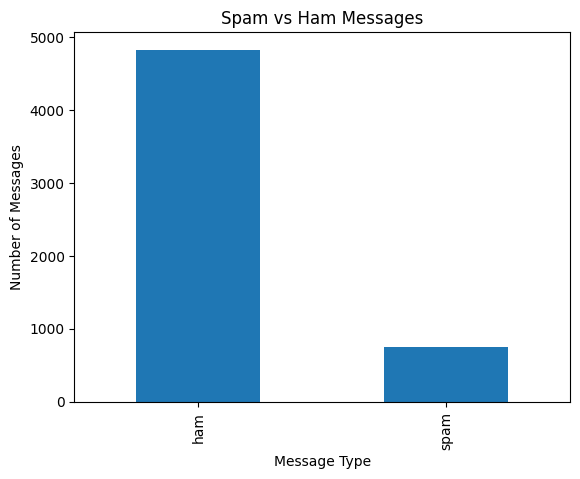

In [6]:
df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Messages",
    xlabel="Message Type",
    ylabel="Number of Messages"
)

In [7]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from nltk.stem import PorterStemmer

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [8]:
stop_words = set(stopwords.words('english'))

# Keep negation words because they can change meaning
stop_words = stop_words - {'no', 'not', 'nor'}

stemmer = PorterStemmer()

def clean_text(text):
    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove numbers and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 3. Split text into words
    tokens = wordpunct_tokenize(text)

    # 4. Remove stopwords and apply stemming
    cleaned_words = [
        stemmer.stem(word)
        for word in tokens
        if word not in stop_words
    ]

    # 5. Join words into a sentence
    return ' '.join(cleaned_words)

In [9]:
#Apply preprocessing to your dataset
df['clean_message'] = df['message'].apply(clean_text)

df[['message', 'clean_message']].head(10)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week no word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month u r entitl updat latest colour mob...


In [10]:
# Separate the input and output
X = df['clean_message']
y = df['label']

print("Input data:")
print(X.head())

print("\nOutput labels:")
print(y.head())

Input data:
0    go jurong point crazi avail bugi n great world...
1                                ok lar joke wif u oni
2    free entri wkli comp win fa cup final tkt st m...
3                  u dun say earli hor u c alreadi say
4                 nah think goe usf live around though
Name: clean_message, dtype: object

Output labels:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [11]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total messages:", len(df))
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Total messages: 5572
Training messages: 4457
Testing messages: 1115


In [12]:
#Import TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

In [13]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 5560)
Testing data shape: (1115, 5560)


In [14]:
print(tfidf.get_feature_names_out()[:20])
print(X_train_tfidf[0].toarray())

['aa' 'aah' 'aaniy' 'aathi' 'ab' 'abbey' 'abdomen' 'abeg' 'abel'
 'aberdeen' 'abi' 'abil' 'abiola' 'abj' 'abl' 'abnorm' 'abouta' 'absenc'
 'absolut' 'absolutli']
[[0. 0. 0. ... 0. 0. 0.]]


In [15]:
#Train the Machine Learning Model
from sklearn.naive_bayes import MultinomialNB

In [16]:
model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [17]:
y_pred = model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred[:10])

Actual labels:
['ham', 'ham', 'ham', 'spam', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham']

Predicted labels:
['ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [23]:
msg = ["Congratulations! You won a free prize"]

msg_tfidf = tfidf.transform([clean_text(msg[0])])

prediction = model.predict(msg_tfidf)

print("Prediction:", prediction[0])

Prediction: spam


In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100)

Accuracy: 96.7713004484305


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



Important Python functions to remember
Function

Purpose

read_csv()

Reads a dataset into pandas

head()

Displays the first few rows

shape

Shows rows and columns

isnull()

Detects missing values

value_counts()

Counts occurrences of each value

lower()

Converts text to lowercase

re.sub()

Replaces matching text

wordpunct_tokenize()

Splits text into tokens

stem()

Reduces a word to its stem

apply()

Applies a function to pandas values

train_test_split()

Splits data into training and testing sets

fit_transform()

Learns feature settings and transforms training data

transform()

Applies learned feature settings to new data

fit()

Trains the model

predict()

Predicts class labels

accuracy_score()

Calculates accuracy

classification_report()

Reports precision, recall, F1-score, and support

